# Book Recommender System on a Medallion Data Lake


**Assignment:** Recommender System using a Bronze–Silver–Gold Data Lake

**Name:** Samayita Mohanta

**Roll No.:** MSD25004

This notebook takes the raw Book-Crossing dataset (`BX-Users`, `BX-Books`, `BX-Book-Ratings`) through a simulated medallion data lake in Google Colab and uses the final Gold data to build one recommender system that suggests books to a user.


## Step 1: Set Up the Data Lake and Build the Bronze Layer

### 1.1 Imports and folder structure
The lake is created under `/content/data_lake` in Colab

In [1]:
import os, re, html, datetime, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
BAR = "#257de0"   # single-series colour used for every chart

BASE_DIR = "/content" if os.path.isdir("/content") else os.getcwd()
DATA_LAKE = os.path.join(BASE_DIR, "data_lake")
BRONZE, SILVER, GOLD = (os.path.join(DATA_LAKE, x) for x in ("bronze", "silver", "gold"))
for d in (BRONZE, SILVER, GOLD):
    os.makedirs(d, exist_ok=True)

print("Data lake root:", DATA_LAKE)
for d in sorted(os.listdir(DATA_LAKE)):
    print("  ", d + "/")

Data lake root: /content/data_lake
   bronze/
   gold/
   silver/


### 1.2 Getting the three raw files
If `BX-Users.csv`, `BX-Books.csv` and `BX-Book-Ratings.csv` have been uploaded to the Colab working folder (Files pane → Upload), they are used directly. Otherwise the original Book-Crossing CSV dump is downloaded from a public GitHub mirror.

In [2]:
RAW_FILES = ["BX-Users.csv", "BX-Books.csv", "BX-Book-Ratings.csv"]

raw_paths = {}
for f in RAW_FILES:
    uploaded = os.path.join(BASE_DIR, f)
    if os.path.isfile(uploaded):
        raw_paths[f] = uploaded
        print(f"{f:22s} found in working folder")
    else:
        raise FileNotFoundError(f"{f} not found. Please upload it to /content (Files pane -> Upload) or add it from Google Drive.")
    print(f"{'':22s} {os.path.getsize(raw_paths[f]) / 1e6:6.1f} MB")

BX-Users.csv           found in working folder
                         12.3 MB
BX-Books.csv           found in working folder
                         77.8 MB
BX-Book-Ratings.csv    found in working folder
                         30.7 MB


### 1.3 Reading the raw files
The first lines are printed to confirm the format: fields are separated by `;`, every value is wrapped in double quotes, and missing ages are written as the literal `NULL`. The files are Latin-1 encoded (not UTF-8), and some book titles contain backslash-escaped quotes (`\"`), which would shift columns if not handled.

In [3]:
for f in RAW_FILES:
    with open(raw_paths[f], "r", encoding="latin-1") as fh:
        print(f"--- {f}")
        for _ in range(3):
            print(fh.readline().rstrip()[:150])

--- BX-Users.csv
"User-ID";"Location";"Age"
"1";"nyc, new york, usa";NULL
"2";"stockton, california, usa";"18"
--- BX-Books.csv
"ISBN";"Book-Title";"Book-Author";"Year-Of-Publication";"Publisher";"Image-URL-S";"Image-URL-M";"Image-URL-L"
"0195153448";"Classical Mythology";"Mark P. O. Morford";"2002";"Oxford University Press";"http://images.amazon.com/images/P/0195153448.01.THUMBZZZ.jpg
"0002005018";"Clara Callan";"Richard Bruce Wright";"2001";"HarperFlamingo Canada";"http://images.amazon.com/images/P/0002005018.01.THUMBZZZ.jpg";"http
--- BX-Book-Ratings.csv
"User-ID";"ISBN";"Book-Rating"
"276725";"034545104X";"0"
"276726";"0155061224";"5"


### 1.4 Loading the files exactly as they are
Reading choices, and why:

- `sep=";"` and `encoding="latin-1"`: the format of the source files.
- `escapechar="\\"`: about a dozen title rows contain `\"`.
- `dtype=str`: every column is kept as text so nothing is changed at read time.

No cleaning is done here. The only thing added is the `ingestion_timestamp`.

In [4]:
READ_OPTS = dict(sep=";", encoding="latin-1", dtype=str, escapechar="\\")

ingestion_ts = pd.Timestamp.now(tz="UTC").floor("s")
bronze = {}
for name, f in [("users", "BX-Users.csv"), ("books", "BX-Books.csv"), ("ratings", "BX-Book-Ratings.csv")]:
    df = pd.read_csv(raw_paths[f], **READ_OPTS)
    with open(raw_paths[f], encoding="latin-1") as fh:
        n_lines = sum(1 for _ in fh) - 1          # minus header
    df["ingestion_timestamp"] = ingestion_ts
    bronze[name] = df
    embedded = df.apply(lambda c: c.astype(str).str.contains("\n", regex=False)).any(axis=1).sum()
    print(f"{name:8s} rows read = {len(df):>9,}   lines in file = {n_lines:>9,}   "
          f"records with an embedded newline = {embedded}   columns = {df.shape[1]}")

users    rows read =   278,858   lines in file =   278,859   records with an embedded newline = 1   columns = 4
books    rows read =   271,379   lines in file =   271,379   records with an embedded newline = 0   columns = 9
ratings  rows read = 1,149,780   lines in file = 1,149,780   records with an embedded newline = 0   columns = 4


For books and ratings, the number of rows read equals the number of data lines in the file. Users has one more line than rows because one quoted `Location` (user 275081, `"cernusco s\n, milan, italy"`) contains a line break inside the quotes.

### 1.5 Saving the Bronze tables as Parquet

In [5]:
for name, df in bronze.items():
    path = os.path.join(BRONZE, f"{name}.parquet")
    df.to_parquet(path, index=False)
    print(f"bronze/{name}.parquet  {os.path.getsize(path) / 1e6:6.1f} MB")

bronze/users.parquet     4.5 MB
bronze/books.parquet    21.7 MB
bronze/ratings.parquet     9.8 MB


## Step 2: Explore the Bronze Data (EDA)

The Bronze tables are read back from Parquet so the EDA works on what was actually stored in the lake.

In [6]:
users_b   = pd.read_parquet(os.path.join(BRONZE, "users.parquet"))
books_b   = pd.read_parquet(os.path.join(BRONZE, "books.parquet"))
ratings_b = pd.read_parquet(os.path.join(BRONZE, "ratings.parquet"))
users_b.head()

,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",None,2026-11-26 15:06:16+00:00
1,2,"stockton, california, usa",18,2026-11-26 15:06:16+00:00
2,3,"moscow, yukon territory, russia",None,2026-11-26 15:06:16+00:00
3,4,"porto, v.n.gaia, portugal",17,2026-11-26 15:06:16+00:00
4,5,"farnborough, hants, united kingdom",None,2026-11-26 15:06:16+00:00


In [7]:
books_b.drop(columns=["Image-URL-S", "Image-URL-M"]).head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-L,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.01.LZZZZZZZ...,2026-11-26 15:06:16+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.01.LZZZZZZZ...,2026-11-26 15:06:16+00:00
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.01.LZZZZZZZ...,2026-11-26 15:06:16+00:00
3,0374157065,Flu: The Story of the Great Influenza Pandemic of 1918 a...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.01.LZZZZZZZ...,2026-11-26 15:06:16+00:00
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.01.LZZZZZZZ...,2026-11-26 15:06:16+00:00


In [8]:
ratings_b.head()

,User-ID,ISBN,Book-Rating,ingestion_timestamp
0,276725,034545104X,0,2026-11-26 15:06:16+00:00
1,276726,0155061224,5,2026-11-26 15:06:16+00:00
2,276727,0446520802,0,2026-11-26 15:06:16+00:00
3,276729,052165615X,3,2026-11-26 15:06:16+00:00
4,276729,0521795028,6,2026-11-26 15:06:16+00:00


### 2.1 Shape, data types and missing values

In [9]:
for name, df in [("users", users_b), ("books", books_b), ("ratings", ratings_b)]:
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2)})
    print(f"\n{name.upper()}  shape = {df.shape}")
    print(info.to_string())

print("\nExact duplicate rows (ignoring ingestion_timestamp):")
for name, df in [("users", users_b), ("books", books_b), ("ratings", ratings_b)]:
    print(f"  {name:8s}", df.drop(columns="ingestion_timestamp").duplicated().sum())
print("Repeated keys: User-ID", users_b["User-ID"].duplicated().sum(),
      "| ISBN", books_b["ISBN"].duplicated().sum(),
      "| (User-ID, ISBN)", ratings_b.duplicated(["User-ID", "ISBN"]).sum())


USERS  shape = (278858, 4)
                                   dtype  missing  missing_%
User-ID                           object        0       0.00
Location                          object        0       0.00
Age                               object   110762      39.72
ingestion_timestamp  datetime64[us, UTC]        0       0.00

BOOKS  shape = (271379, 9)
                                   dtype  missing  missing_%
ISBN                              object        0        0.0
Book-Title                        object        0        0.0
Book-Author                       object        2        0.0
Year-Of-Publication               object        0        0.0
Publisher                         object        2        0.0
Image-URL-S                       object        0        0.0
Image-URL-M                       object        0        0.0
Image-URL-L                       object        0        0.0
ingestion_timestamp  datetime64[us, UTC]        0        0.0

RATINGS  shape = (1149780, 4

**Observation.**
- **Users**: `Age` is missing for 110,762 users (39.7%). `Location` is one free-text field. **Silver:**  `Age` to be fixed and imputed and `Location` is split into three columns.
- **Books**: only 2 authors and 2 publishers are missing, but the year is stored as text and three columns are image URLs that the recommender will never use. **Silver:** casting `year` to a number and the URL columns to be dropped.
- **Ratings**: no missing values. `Book-Rating` is stored as text. **Silver:** cast it to an integer.
- No exact duplicates or repeated keys were found in the raw files. The duplicate removal step is still applied in Silver, because some duplicates only show up after text cleaning (for example ISBNs ending in `x` vs `X`).

### 2.2 Distribution of ratings

              count  share_%
Book-Rating                 
0            716109    62.28
1              1770     0.15
2              2759     0.24
3              5996     0.52
4              8904     0.77
5             50974     4.43
6             36924     3.21
7             76457     6.65
8            103736     9.02
9             67541     5.87
10            78610     6.84

Ratings equal to 0: 716,109 of 1,149,780 (62.3%)


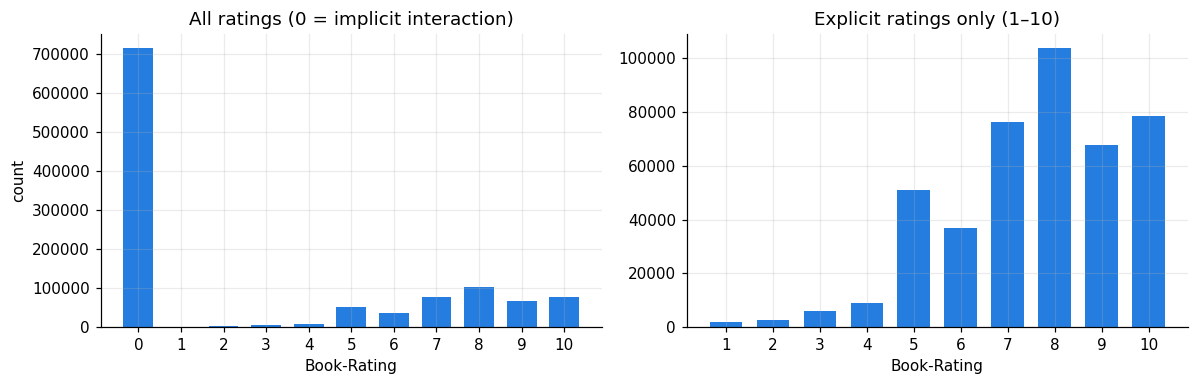

In [10]:
rating_num = pd.to_numeric(ratings_b["Book-Rating"], errors="coerce")
counts = rating_num.value_counts().sort_index()
print(pd.DataFrame({"count": counts, "share_%": (counts / counts.sum() * 100).round(2)}).to_string())
print(f"\nRatings equal to 0: {(rating_num == 0).sum():,} of {len(rating_num):,} "
      f"({(rating_num == 0).mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(counts.index, counts.values, color=BAR, width=0.7)
axes[0].set_title("All ratings (0 = implicit interaction)")
axes[0].set_xticks(range(0, 11)); axes[0].set_xlabel("Book-Rating"); axes[0].set_ylabel("count")
exp = counts.drop(0)
axes[1].bar(exp.index, exp.values, color=BAR, width=0.7)
axes[1].set_title("Explicit ratings only (1–10)")
axes[1].set_xticks(range(1, 11)); axes[1].set_xlabel("Book-Rating")
plt.tight_layout(); plt.show()

**Observation.** 716,109 of 1,149,780 ratings (62.3%) are **0**, which in Book-Crossing means the user handled the book but did not score it, not a low score. The 433,671 explicit ratings are strongly skewed towards the top: 8 is the most common score and ratings 1–4 together are only about 1.7% of all rows, so users mostly rate books they liked. **Silver:** every 0 is dropped and only 1–10 is kept.

### 2.3 Distribution of user ages and publication years

Age summary:
 count    168096.0
mean         34.8
std          14.4
min           0.0
25%          24.0
50%          32.0
75%          44.0
max         244.0
Age missing: 110,762 | age < 5: 882 | age > 100: 366

Publication year summary:
 count    271379.0
mean       1959.8
std         258.0
min           0.0
25%        1989.0
50%        1995.0
75%        2000.0
max        2050.0
Year = 0: 4,619 | year > 2026: 11 | non-numeric: 0
Future years found: [np.int64(2030), np.int64(2037), np.int64(2038), np.int64(2050)]


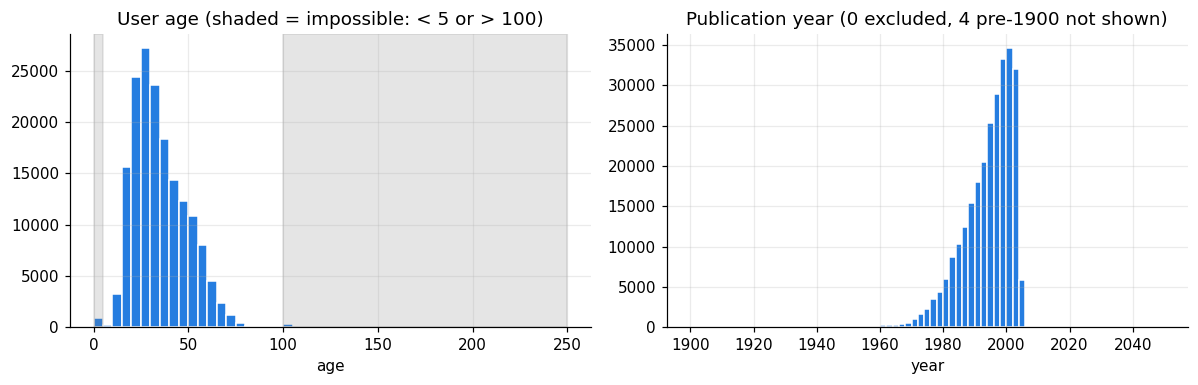

In [11]:
age = pd.to_numeric(users_b["Age"], errors="coerce")
year = pd.to_numeric(books_b["Year-Of-Publication"], errors="coerce")
CURRENT_YEAR = datetime.date.today().year

print("Age summary:\n", age.describe().round(1).to_string())
print(f"Age missing: {age.isna().sum():,} | age < 5: {(age < 5).sum():,} | age > 100: {(age > 100).sum():,}")
print("\nPublication year summary:\n", year.describe().round(1).to_string())
print(f"Year = 0: {(year == 0).sum():,} | year > {CURRENT_YEAR}: {(year > CURRENT_YEAR).sum():,} "
      f"| non-numeric: {year.isna().sum():,}")
print("Future years found:", sorted(year[year > CURRENT_YEAR].astype(int).unique()))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(age.dropna(), bins=range(0, 250, 5), color=BAR, edgecolor="white")
axes[0].axvspan(0, 5, color="grey", alpha=0.2); axes[0].axvspan(100, 250, color="grey", alpha=0.2)
axes[0].set_title("User age (shaded = impossible: < 5 or > 100)"); axes[0].set_xlabel("age")
axes[1].hist(year[year > 0], bins=range(1900, 2051, 2), color=BAR, edgecolor="white")
axes[1].set_title(f"Publication year (0 excluded, {((year > 0) & (year < 1900)).sum()} pre-1900 not shown)")
axes[1].set_xlabel("year")
plt.tight_layout(); plt.show()

**Observation.**
- **Ages:** besides 39.7% missing, 1,248 values are impossible (882 below 5, including many 0s, and 366 above 100, with a maximum of 244). The valid ages are right-skewed with a median of 32. **Silver:** set ages below 5 or above 100 to null and fill all nulls with the median (32), with a flag column so imputed ages can still be identified.
- **Publication year:** 4,619 books have year 0 (a placeholder for "unknown") and 11 have future years (2030, 2037, 2038, 2050). The oldest value, 1376, is unusual but possible for a classic text, so it is kept. **Silver:** set 0 and future years to null.

### 2.4 Number of ratings per user and per book
Only explicit ratings (1–10) are counted here, because those are what the recommender will learn from.

       per_user  per_book
count   77805.0  185973.0
mean        5.6       2.3
std        44.0       6.8
min         1.0       1.0
50%         1.0       1.0
75%         3.0       2.0
90%         9.0       4.0
95%        19.0       6.0
99%        73.0      22.0
max      8524.0     707.0
users: exactly 1 rating = 58.3%, at least 10 ratings = 9.4%
books: exactly 1 rating = 69.7%, at least 10 ratings = 3.0%


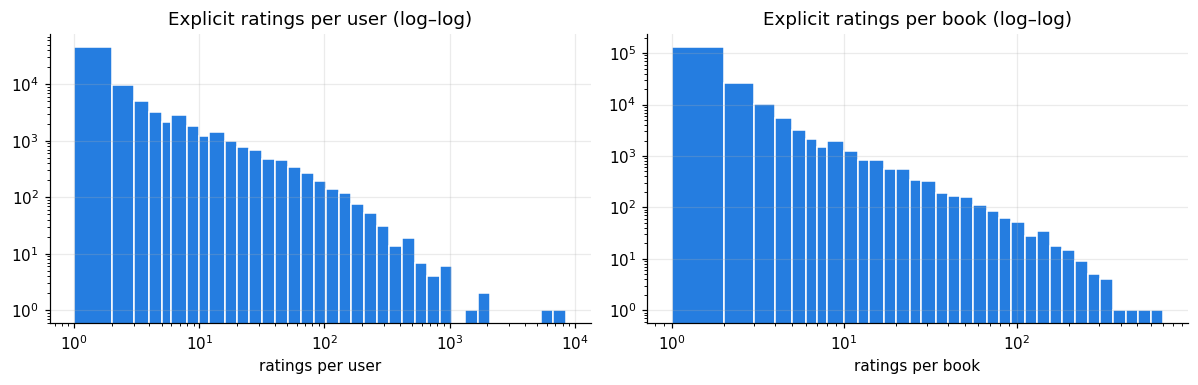

In [12]:
explicit_b = ratings_b[rating_num > 0]
per_user = explicit_b.groupby("User-ID").size()
per_book = explicit_b.groupby("ISBN").size()

pct = [0.5, 0.75, 0.9, 0.95, 0.99]
summary = pd.DataFrame({"per_user": per_user.describe(percentiles=pct),
                        "per_book": per_book.describe(percentiles=pct)}).round(1)
print(summary.to_string())
for label, s in [("users", per_user), ("books", per_book)]:
    print(f"{label}: exactly 1 rating = {(s == 1).mean():.1%}, at least 10 ratings = {(s >= 10).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, s, label in [(axes[0], per_user, "user"), (axes[1], per_book, "book")]:
    bins = np.unique(np.logspace(0, np.log10(s.max() + 1), 40).astype(int))
    ax.hist(s, bins=bins, color=BAR, edgecolor="white")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"Explicit ratings per {label} (log–log)"); ax.set_xlabel(f"ratings per {label}")
plt.tight_layout(); plt.show()

**Observation.** Activity has a long-tail (power-law) shape, which is a straight line on the log–log plots. The **median is 1 explicit rating per user and 1 per book**. 58.3% of users and 69.7% of books have exactly one explicit rating, and only 9.4% of users and 3.0% of books reach 10. At the other end, a few power users have thousands of ratings (maximum 8,524). A book with one rating has no co-raters, so its similarity to any other book cannot be estimated. **Silver:** apply a minimum-ratings filter on both users and books.

### 2.5 Matrix sparsity

In [13]:
def sparsity_report(df, label):
    n_u, n_b, n_r = df["User-ID"].nunique(), df["ISBN"].nunique(), len(df)
    density = n_r / (n_u * n_b)
    print(f"{label:28s} users={n_u:>7,}  books={n_b:>7,}  ratings={n_r:>9,}  "
          f"filled={density:.5%}  sparsity={1 - density:.5%}")

sparsity_report(ratings_b, "All Bronze ratings")
sparsity_report(explicit_b, "Explicit ratings (1-10)")

All Bronze ratings           users=105,283  books=340,556  ratings=1,149,780  filled=0.00321%  sparsity=99.99679%
Explicit ratings (1-10)      users= 77,805  books=185,973  ratings=  433,671  filled=0.00300%  sparsity=99.99700%


### 2.6 Choosing the minimum-ratings threshold
To justify the threshold for Step 3, the explicit ratings that link to known users and books are filtered at several cut-offs. Removing light users makes some books fall below the cut-off and the other way round, so the filter is repeated until nothing changes (a "k-core").

In [14]:
def k_core(df, k_user, k_book, max_iter=50):
    for _ in range(max_iter):
        before = len(df)
        df = df[df.groupby("User-ID")["ISBN"].transform("size") >= k_user]
        df = df[df.groupby("ISBN")["User-ID"].transform("size") >= k_book]
        if len(df) == before:
            break
    return df

_tmp = explicit_b.assign(ISBN=explicit_b["ISBN"].str.strip().str.upper())
_tmp = _tmp[_tmp["ISBN"].isin(set(books_b["ISBN"].str.strip().str.upper()))
            & _tmp["User-ID"].isin(set(users_b["User-ID"]))]

rows = []
for k in [1, 3, 5, 8, 10, 12, 15, 20]:
    kc = k_core(_tmp, k, k)
    nu, nb = kc["User-ID"].nunique(), kc["ISBN"].nunique()
    rows.append({"min_ratings": k, "ratings": len(kc), "users": nu, "books": nb,
                 "density_%": round(100 * len(kc) / (nu * nb), 3) if nu else np.nan})
threshold_table = pd.DataFrame(rows)
threshold_table

,min_ratings,ratings,users,books,density_%
0,1,383853,68092,149723,0.004
1,3,183649,14523,22667,0.056
2,5,115332,6858,9092,0.185
3,8,62546,2934,3481,0.612
4,10,41469,1820,2030,1.122
5,12,21666,918,977,2.416
6,15,0,0,0,NaN
7,20,0,0,0,NaN


**Observation and threshold decision.** The table shows the trade-off clearly. At k = 5 there are 115k ratings, but the density is only 0.19%, and most books would be compared on about five co-raters, which gives noisy cosine values. At k = 12 the data halves to 918 users. At **k ≥ 15 the core collapses to nothing**

**I chose a minimum of 10 ratings per user and per book (applied until stable).** It is the strictest value that still keeps a reasonable model: 41,469 ratings from 1,820 users on 2,030 books. The density rises from 0.003% to 1.12% (about 370 times denser), and every book has at least 10 raters for the similarity to be based on. The cost is that the recommender only covers the most active part of the community and cannot serve cold-start users.

### 2.7 Other issues noticed in the text columns

In [15]:
loc_parts = users_b["Location"].str.count(",") + 1
print("Number of comma-separated parts in Location:\n", loc_parts.value_counts().sort_index().head(8).to_string())
print("\nExamples of odd locations:", users_b.loc[loc_parts != 3, "Location"].head(5).tolist())
print("\nTitles with HTML entities (&amp; etc.):", books_b["Book-Title"].str.contains(r"&\w+;", regex=True).sum())
print("Titles/authors with leading, trailing or double spaces:",
      books_b["Book-Title"].str.contains(r"^\s|\s$|\s{2,}", regex=True).sum(), "/",
      books_b["Book-Author"].str.contains(r"^\s|\s$|\s{2,}", regex=True, na=False).sum())
print("Rating ISBNs that are not in the books table:",
      (~ratings_b["ISBN"].isin(set(books_b["ISBN"]))).sum())
print("Rating ISBNs with lowercase letters or spaces:",
      ratings_b["ISBN"].str.contains(r"[a-z\s]", regex=True).sum())
print("Example author spellings:", books_b.loc[books_b["Book-Author"].str.lower() == "stephen king", "Book-Author"].unique()[:5])

Number of comma-separated parts in Location:
 Location
1         1
2         1
3    277348
4      1417
5        72
6        11
7         4
8         2

Examples of odd locations: ['ivanhoe, melbourne, victoria, australia', 'davis bay, sechelt, british columbia, canada', 'saint charles, mo, missouri, usa', 'santiago, santiago,metropolitana, chile', 'mansoura, dakahlia, mansoura, egypt']

Titles with HTML entities (&amp; etc.): 4908
Titles/authors with leading, trailing or double spaces: 2505 / 1321
Rating ISBNs that are not in the books table: 118605
Rating ISBNs with lowercase letters or spaces: 658
Example author spellings: ['Stephen King' 'STEPHEN KING']


**Observation.**
- **Location:** About 1,500 locations have more than three comma-separated parts (for example `saint charles, mo, missouri, usa`).
- **Titles and authors:** 4,908 titles contain HTML entities such as `&amp;`, about 3,600 titles or authors have extra spaces, and the same author appears in different cases (`Stephen King` / `STEPHEN KING`).
- **ISBNs:** 118,605 rating rows point to an ISBN that is not in the books table, and 658 rating ISBNs contain lower-case letters or spaces.

## Step 3: Clean the Data and Build the Silver Layer
Each rule from the assignment is applied in order, with a row count after every step so the effect of each rule can be traced.

In [16]:
users   = users_b.drop(columns="ingestion_timestamp").copy()
books   = books_b.drop(columns="ingestion_timestamp").copy()
ratings = ratings_b.drop(columns="ingestion_timestamp").copy()

log = []
def track(step, **tables):
    log.append({"step": step, **{k: len(v) for k, v in tables.items()}})

track("Bronze", users=users, books=books, ratings=ratings)

### 3.1 Clean text columns, standardise case and drop image URLs
Text is cleaned first, so that duplicate detection in the next step also catches rows that differ only by spaces or case.

- **All text:** strip leading/trailing spaces and collapse repeated spaces; empty strings become null.
- **Titles, authors, publishers:** HTML entities are decoded (`&amp;` → `&`) and text is lower-cased and the first letter of each word is capitalised, so `stephen king` and `STEPHEN KING` both become `Stephen King`. A small regex is used instead of `str.title()`, which turns *Sorcerer's* into *Sorcerer'S*.
- **ISBN:** trimmed and upper-cased, in both the books and ratings tables.
- **Location:** lower-cased.
- The three `Image-URL-*` columns are dropped because the recommender only shows text.

In [17]:
def clean_text(s):
    s = s.astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
    return s.replace("", pd.NA)

WORD_START = re.compile(r"(^|[\s(\[\"/.\-])([a-z])")

def smart_title(v):
    # lower-case everything, then capitalise the first letter after a space, bracket, quote, slash,
    # dot or hyphen. Apostrophes are not word starts, so "sorcerer's" stays "Sorcerer's".
    v = html.unescape(v).lower()
    return WORD_START.sub(lambda m: m.group(1) + m.group(2).upper(), v)

def capwords_series(s):
    uniq = s.dropna().unique()
    mapping = {v: smart_title(v) for v in uniq}
    return s.map(mapping).astype("string")

books = books.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"])
for c in ["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication", "Publisher"]:
    books[c] = clean_text(books[c])
for c in ["Book-Title", "Book-Author", "Publisher"]:
    books[c] = capwords_series(books[c])
books["ISBN"] = books["ISBN"].str.upper()

users["User-ID"] = clean_text(users["User-ID"])
users["Location"] = clean_text(users["Location"]).str.lower()
ratings["User-ID"] = clean_text(ratings["User-ID"])
ratings["ISBN"] = clean_text(ratings["ISBN"]).str.upper()

books.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada
2,0060973129,Decision In Normandy,Carlo D'este,1991,Harperperennial
3,0374157065,Flu: The Story Of The Great Influenza Pandemic Of 1918 A...,Gina Bari Kolata,1999,Farrar Straus Giroux
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company


### 3.2 Remove duplicate rows
Exact duplicates are removed first. Then the keys are made unique: one row per `User-ID`, one row per `ISBN`, and one rating per (`User-ID`, `ISBN`) pair (the last one is kept, as it is the most recent).

In [18]:
users   = users.drop_duplicates().drop_duplicates("User-ID", keep="first")
books   = books.drop_duplicates().drop_duplicates("ISBN", keep="first")
ratings = ratings.drop_duplicates().drop_duplicates(["User-ID", "ISBN"], keep="last")
track("Text cleaned + duplicates removed", users=users, books=books, ratings=ratings)
print(pd.DataFrame(log).set_index("step").diff().iloc[-1].rename("rows removed").to_string())

users        0.0
books     -315.0
ratings      0.0


### 3.3 Remove ratings of 0, keep 1–10

In [19]:
ratings["Book-Rating"] = pd.to_numeric(ratings["Book-Rating"], errors="coerce")
ratings = ratings[ratings["Book-Rating"].between(1, 10)].copy()
ratings["Book-Rating"] = ratings["Book-Rating"].astype("int8")
track("Ratings 1-10 only", users=users, books=books, ratings=ratings)
print("Rating values left:", sorted(ratings["Book-Rating"].unique()), "| rows:", f"{len(ratings):,}")

Rating values left: [np.int8(1), np.int8(2), np.int8(3), np.int8(4), np.int8(5), np.int8(6), np.int8(7), np.int8(8), np.int8(9), np.int8(10)] | rows: 433,671


### 3.4 Fix user ages
Ages below 5 or above 100 are set to null, then all nulls (original and new) are filled with the median of the valid ages. The median is used rather than the mean because the age distribution is right-skewed.

In [20]:
users["Age"] = pd.to_numeric(users["Age"], errors="coerce")
invalid_age = (users["Age"] < 5) | (users["Age"] > 100)
print(f"Ages set to null as impossible: {invalid_age.sum():,}")
users.loc[invalid_age, "Age"] = np.nan
median_age = users["Age"].median()
print(f"Nulls to fill: {users['Age'].isna().sum():,}  | median of valid ages = {median_age}")
users["age_was_imputed"] = users["Age"].isna()
users["Age"] = users["Age"].fillna(median_age).round().astype("int16")
users["Age"].describe().round(1)

Ages set to null as impossible: 1,248
Nulls to fill: 112,010  | median of valid ages = 32.0


,Age
count,278858.0
mean,33.6
std,10.6
min,5.0
25%,29.0
50%,32.0
75%,35.0
max,100.0


### 3.5 Split Location into city, state and country


In [21]:
PLACEHOLDERS = {"", "n/a", "na", "none", "null", "-", ".", "?", "unknown", '"'}

def split_location(loc):
    if pd.isna(loc):
        return (pd.NA, pd.NA, pd.NA)
    parts = [p.strip() for p in str(loc).split(",")]
    parts = [pd.NA if p in PLACEHOLDERS else p for p in parts]
    if len(parts) == 1:
        return (parts[0], pd.NA, pd.NA)
    if len(parts) == 2:
        return (parts[0], pd.NA, parts[1])
    middle = [p for p in parts[1:-1] if not pd.isna(p)]
    return (parts[0], ", ".join(middle) if middle else pd.NA, parts[-1])

uniq_loc = users["Location"].dropna().unique()
loc_map = {l: split_location(l) for l in uniq_loc}
split = users["Location"].map(loc_map)
users["city"]    = split.str[0].astype("string")
users["state"]   = split.str[1].astype("string")
users["country"] = split.str[2].astype("string")
users = users.drop(columns="Location")

print(users[["city", "state", "country"]].isna().mean().mul(100).round(1).rename("missing %").to_string())
print("\nTop countries:\n", users["country"].value_counts().head(8).to_string())
users.head()

city       0.2
state      5.9
country    1.7

Top countries:
 country
usa               139712
canada             21658
united kingdom     18556
germany            17073
spain              13258
australia          11785
italy              11271
france              3487


,User-ID,Age,age_was_imputed,city,state,country
0,1,32,True,nyc,new york,usa
1,2,18,False,stockton,california,usa
2,3,32,True,moscow,yukon territory,russia
3,4,17,False,porto,v.n.gaia,portugal
4,5,32,True,farnborough,hants,united kingdom


### 3.6 Fix publication years
Year 0 and any year later than the current year are set to null. The column becomes a nullable integer, so the books are kept and only the irrelevant year is removed.

In [22]:
books["Year-Of-Publication"] = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
bad_year = (books["Year-Of-Publication"] == 0) | (books["Year-Of-Publication"] > CURRENT_YEAR)
print(f"Years set to null: {bad_year.sum():,} (0 or > {CURRENT_YEAR})")
books.loc[bad_year, "Year-Of-Publication"] = np.nan
books["Year-Of-Publication"] = books["Year-Of-Publication"].astype("Int16")
books["Year-Of-Publication"].describe().round(1)

Years set to null: 4,623 (0 or > 2026)


,Year-Of-Publication
count,266441.0
mean,1993.7
std,8.3
min,1376.0
25%,1989.0
50%,1996.0
75%,2000.0
max,2026.0


### 3.7 Keep only ratings whose book and user exist

In [23]:
known_user = ratings["User-ID"].isin(set(users["User-ID"]))
known_book = ratings["ISBN"].isin(set(books["ISBN"]))
print(f"Ratings with unknown user: {(~known_user).sum():,} | with unknown ISBN: {(~known_book).sum():,}")
ratings = ratings[known_user & known_book].copy()
track("Ratings with known user and book", users=users, books=books, ratings=ratings)
print(f"Ratings kept: {len(ratings):,}")

Ratings with unknown user: 0 | with unknown ISBN: 49,818
Ratings kept: 383,853


### 3.8 Minimum activity filter (threshold = 10)
**Threshold chosen: at least 10 explicit ratings per user and at least 10 per book**.

In [24]:
MIN_RATINGS = 10
ratings = k_core(ratings, MIN_RATINGS, MIN_RATINGS)
users = users[users["User-ID"].isin(set(ratings["User-ID"]))].copy()
books = books[books["ISBN"].isin(set(ratings["ISBN"]))].copy()
track(f"Min {MIN_RATINGS} ratings per user and book", users=users, books=books, ratings=ratings)

assert ratings.groupby("User-ID").size().min() >= MIN_RATINGS
assert ratings.groupby("ISBN").size().min() >= MIN_RATINGS
pd.DataFrame(log).set_index("step")

,users,books,ratings
step,,,
Bronze,278858,271379,1149780
Text cleaned + duplicates removed,278858,271064,1149780
Ratings 1-10 only,278858,271064,433671
Ratings with known user and book,278858,271064,383853
Min 10 ratings per user and book,1820,2030,41469


### 3.9 Saving the Silver tables

In [25]:
users = users.rename(columns={"User-ID": "user_id", "Age": "age"})
books = books.rename(columns={"ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
                              "Year-Of-Publication": "year", "Publisher": "publisher"})
ratings = ratings.rename(columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})
for c in ("user_id",):
    users[c] = users[c].astype(int); ratings[c] = ratings[c].astype(int)

for name, df in [("users", users), ("books", books), ("ratings", ratings)]:
    df.reset_index(drop=True).to_parquet(os.path.join(SILVER, f"{name}.parquet"), index=False)
    print(f"silver/{name}.parquet  rows={len(df):>7,}  columns={list(df.columns)}")

silver/users.parquet  rows=  1,820  columns=['user_id', 'age', 'age_was_imputed', 'city', 'state', 'country']
silver/books.parquet  rows=  2,030  columns=['isbn', 'title', 'author', 'year', 'publisher']
silver/ratings.parquet  rows= 41,469  columns=['user_id', 'isbn', 'rating']


**Observation.** The row-count log above shows how each rule shrinks the data:
- Normalising ISBNs exposed **315 duplicate book rows** (the same ISBN written with `x` and `X`, or with spaces).
- Dropping 0-ratings removed **62% of all ratings**.
- Referential integrity removed another **49,818 explicit ratings** whose ISBN is not in the books catalogue. Every rating user does exist in the users table.
- The ≥ 10 activity filter is the biggest cut. It keeps 41,469 ratings (9.6% of the explicit ratings), 1,820 users and 2,030 books.

I reduced the users and books tables to only the IDs that survive, to avoid ambiguity among the three Silver tables.

## Step 4: Build the Gold Layer
The Gold layer is built only from the Silver files.

In [26]:
users_s   = pd.read_parquet(os.path.join(SILVER, "users.parquet"))
books_s   = pd.read_parquet(os.path.join(SILVER, "books.parquet"))
ratings_s = pd.read_parquet(os.path.join(SILVER, "ratings.parquet"))
print(users_s.shape, books_s.shape, ratings_s.shape)

(1820, 6) (2030, 5) (41469, 3)


### 4.1 Sparse user–book rating matrix
Each user and each book get an integer index. The ratings are stored as a SciPy CSR matrix (rows = users, columns = books), saved with `save_npz`, and the two index tables are saved next to it so any row or column can be mapped back to its ID.

In [27]:
user_index = pd.DataFrame({"user_id": np.sort(ratings_s["user_id"].unique())})
user_index["row"] = np.arange(len(user_index))
book_index = pd.DataFrame({"isbn": np.sort(ratings_s["isbn"].unique())})
book_index["col"] = np.arange(len(book_index))

r = (ratings_s.merge(user_index, on="user_id").merge(book_index, on="isbn"))
R = sparse.csr_matrix((r["rating"].astype(np.float32), (r["row"], r["col"])),
                      shape=(len(user_index), len(book_index)))

sparse.save_npz(os.path.join(GOLD, "user_book_matrix.npz"), R)
user_index.to_parquet(os.path.join(GOLD, "user_index.parquet"), index=False)
book_index.to_parquet(os.path.join(GOLD, "book_index.parquet"), index=False)

dense_mb = R.shape[0] * R.shape[1] * 4 / 1e6
sparse_mb = (R.data.nbytes + R.indices.nbytes + R.indptr.nbytes) / 1e6
print(f"Matrix shape (users x books): {R.shape}, stored ratings: {R.nnz:,}")
print(f"Density: {R.nnz / (R.shape[0] * R.shape[1]):.3%}")
print(f"Memory: sparse {sparse_mb:.2f} MB vs dense {dense_mb:.1f} MB")

Matrix shape (users x books): (1820, 2030), stored ratings: 41,469
Density: 1.122%
Memory: sparse 0.34 MB vs dense 14.8 MB


### 4.2 Book lookup table

In [30]:
book_lookup = (book_index.merge(books_s[["isbn", "title", "author", "year", "publisher"]], on="isbn", how="left"))
book_lookup.to_parquet(os.path.join(GOLD, "book_lookup.parquet"), index=False)
book_lookup.head()

,isbn,col,title,author,year,publisher
0,0020199600,0,Great Gatsby (Reissue),F. Scott Fitzgerald,1988,Scribner Paper Fiction
1,0020442203,1,"Lion, The Witch And The Wardrobe",C.S. Lewis,1970,Macmillan Publishing Company.
2,002542730X,2,Politically Correct Bedtime Stories: Modern Tales For Ou...,James Finn Garner,1994,John Wiley & Sons Inc
3,0028604199,3,Once Upon A More Enlightened Time: More Politically Corr...,James Finn Garner,1995,Macmillan Publishing Company.
4,0060002050,4,On A Wicked Dawn (Cynster Novels),Stephanie Laurens,2002,Avon Books


### 4.3 User-level and book-level aggregates

In [31]:
user_stats = (ratings_s.groupby("user_id")["rating"]
              .agg(avg_rating="mean", n_ratings="size").round({"avg_rating": 2}).reset_index()
              .merge(users_s[["user_id", "age", "country"]], on="user_id", how="left"))
book_stats = (ratings_s.groupby("isbn")["rating"]
              .agg(avg_rating="mean", n_ratings="size").round({"avg_rating": 2}).reset_index()
              .merge(book_lookup[["isbn", "title", "author"]], on="isbn", how="left"))
user_stats.to_parquet(os.path.join(GOLD, "user_stats.parquet"), index=False)
book_stats.to_parquet(os.path.join(GOLD, "book_stats.parquet"), index=False)

print("User aggregates:\n", user_stats[["avg_rating", "n_ratings"]].describe().round(2).to_string())
print("\nMost-rated books in Gold:")
book_stats.sort_values("n_ratings", ascending=False).head(8)[["title", "author", "n_ratings", "avg_rating"]]

User aggregates:
        avg_rating  n_ratings
count     1820.00    1820.00
mean         7.95      22.79
std          0.94      28.61
min          4.30      10.00
25%          7.42      12.00
50%          8.00      16.00
75%          8.58      26.00
max         10.00     954.00

Most-rated books in Gold:


,title,author,n_ratings,avg_rating
281,The Lovely Bones: A Novel,Alice Sebold,223,8.24
662,The Da Vinci Code,Dan Brown,177,8.61
205,The Red Tent (Bestselling Backlist),Anita Diamant,132,8.49
176,The Secret Life Of Bees,Sue Monk Kidd,125,8.66
1520,Harry Potter And The Sorcerer's Stone (Harry Potter (Pap...,J. K. Rowling,119,9.04
1100,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts,115,8.30
44,Divine Secrets Of The Ya-Ya Sisterhood: A Novel,Rebecca Wells,113,8.12
869,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,111,9.07


In [32]:
print("Data lake contents:")
for layer in ("bronze", "silver", "gold"):
    for f in sorted(os.listdir(os.path.join(DATA_LAKE, layer))):
        size = os.path.getsize(os.path.join(DATA_LAKE, layer, f)) / 1e6
        print(f"  {layer}/{f:24s} {size:7.2f} MB")

Data lake contents:
  bronze/books.parquet              21.67 MB
  bronze/ratings.parquet             9.84 MB
  bronze/users.parquet               4.49 MB
  silver/books.parquet               0.08 MB
  silver/ratings.parquet             0.11 MB
  silver/users.parquet               0.03 MB
  gold/book_index.parquet          0.03 MB
  gold/book_lookup.parquet         0.09 MB
  gold/book_stats.parquet          0.07 MB
  gold/user_book_matrix.npz        0.10 MB
  gold/user_index.parquet          0.02 MB
  gold/user_stats.parquet          0.02 MB


**Observation.** The Gold matrix is 1,820 users × 2,030 books with 41,469 ratings (1.12% filled). The average user rating is 7.95, and the median user has 16 ratings. The most-rated books are 2002–2003 best-sellers and book-club titles (*The Lovely Bones* with 223 ratings, *The Da Vinci Code* with 177, two Harry Potter books). The 2,030 ISBNs cover only 1,831 distinct titles, because some books appear in several editions. The recommender therefore removes duplicate titles from its output.

## Step 5: Build the Recommender (Item-Based Collaborative Filtering)

### 5.1 Load the Gold matrix and arrange it as book × user


In [33]:
R_gold = sparse.load_npz(os.path.join(GOLD, "user_book_matrix.npz"))
user_index  = pd.read_parquet(os.path.join(GOLD, "user_index.parquet"))
book_index  = pd.read_parquet(os.path.join(GOLD, "book_index.parquet"))
book_lookup = pd.read_parquet(os.path.join(GOLD, "book_lookup.parquet")).set_index("col").sort_index()
book_stats  = pd.read_parquet(os.path.join(GOLD, "book_stats.parquet"))

item_matrix = R_gold.T.tocsr()          # rows = books, columns = users
user_to_row = dict(zip(user_index["user_id"], user_index["row"]))
print("Book x user matrix:", item_matrix.shape, "| non-zeros:", f"{item_matrix.nnz:,}")

Book x user matrix: (2030, 1820) | non-zeros: 41,469


### 5.2 Cosine similarity between books with NearestNeighbors
`NearestNeighbors(metric="cosine", algorithm="brute")` works directly on the sparse matrix. Brute force is needed because tree-based search does not support cosine on sparse input, and with about two thousand books it is fast anyway. The neighbours of every book are computed once and cached, since `recommend()` will use them many times. Similarity = 1 − cosine distance.

In [34]:
K_NEIGHBOURS = 50
knn = NearestNeighbors(metric="cosine", algorithm="brute", n_neighbors=K_NEIGHBOURS + 1, n_jobs=-1)
knn.fit(item_matrix)
dist, idx = knn.kneighbors(item_matrix)

# drop each book itself (it is always its own nearest neighbour at distance 0)
nbr_idx, nbr_sim = [], []
for i in range(item_matrix.shape[0]):
    keep = idx[i] != i
    nbr_idx.append(idx[i][keep][:K_NEIGHBOURS])
    nbr_sim.append(1 - dist[i][keep][:K_NEIGHBOURS])
nbr_idx, nbr_sim = np.vstack(nbr_idx), np.vstack(nbr_sim)

print("Neighbour table:", nbr_idx.shape)
print("Similarity of the closest neighbour: median %.3f, min %.3f, max %.3f"
      % (np.median(nbr_sim[:, 0]), nbr_sim[:, 0].min(), nbr_sim[:, 0].max()))
print("Share of neighbour slots with similarity 0 (no common raters): %.1f%%" % (100 * (nbr_sim <= 0).mean()))

Neighbour table: (2030, 50)
Similarity of the closest neighbour: median 0.292, min 0.138, max 0.898
Share of neighbour slots with similarity 0 (no common raters): 0.0%


### 5.3 `similar_books(title)`: the 10 most similar books
The title search is case-insensitive. If an exact match is not found, the function falls back to titles that contain the search text. If several editions (ISBNs) share the title, the one with the most ratings is used. Other editions of the same title are removed from the results, so the list is not filled with copies of the query book.

In [35]:
title_key = book_lookup["title"].str.lower()
n_ratings_col = book_stats.set_index("isbn")["n_ratings"]
book_lookup["n_ratings"] = book_lookup["isbn"].map(n_ratings_col)

def find_book(title):
    q = title.strip().lower()
    hits = book_lookup[title_key == q]
    if hits.empty:
        hits = book_lookup[title_key.str.contains(re.escape(q))]
    if hits.empty:
        raise ValueError(f"No book matching '{title}' in the Gold layer")
    return hits["n_ratings"].idxmax()        # column index of the most-rated edition

def similar_books(title, n=10):
    col = find_book(title)
    query_title = book_lookup.at[col, "title"].lower()
    out, seen = [], {query_title}
    for j, s in zip(nbr_idx[col], nbr_sim[col]):
        t = book_lookup.at[j, "title"]
        if s <= 0 or t.lower() in seen:
            continue
        seen.add(t.lower())
        out.append({"title": t, "author": book_lookup.at[j, "author"], "similarity": round(float(s), 3)})
        if len(out) == n:
            break
    print(f"Books most similar to: {book_lookup.at[col, 'title']} — {book_lookup.at[col, 'author']}")
    return pd.DataFrame(out, index=range(1, len(out) + 1))

similar_books("Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback))")

Books most similar to: Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)) — J. K. Rowling


,title,author,similarity
1,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,0.411
2,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,0.316
3,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,0.254
4,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,0.243
5,Fried Green Tomatoes At The Whistle Stop Cafe,Fannie Flagg,0.189
6,Love Story,Erich Segal,0.170
7,Anne Of Green Gables (Anne Of Green Gables Novels (Paper...,L.M. Montgomery,0.163
8,Anne Of Ingleside (Anne Of Green Gables Novels (Paperback)),L.M. Montgomery,0.156
9,Like Water For Chocolate: A Novel In Monthly Installment...,Laura Esquivel,0.155
10,"Blood Of The Fold (Sword Of Truth, Book 3)",Terry Goodkind,0.154


In [36]:
similar_books("The Da Vinci Code")

Books most similar to: The Da Vinci Code — Dan Brown


,title,author,similarity
1,Angels & Demons,Dan Brown,0.240
2,The Lovely Bones: A Novel,Alice Sebold,0.178
3,The Narrows: A Novel,Michael Connelly,0.176
4,Middlesex: A Novel,Jeffrey Eugenides,0.175
5,Sea Glass: A Novel,Anita Shreve,0.162
6,No Second Chance,Harlan Coben,0.160
7,The Face,Dean Koontz,0.158
8,Nights In Rodanthe,Nicholas Sparks,0.156
9,The Secret Life Of Bees,Sue Monk Kidd,0.156
10,The Conspiracy Club,Jonathan Kellerman,0.151


In [37]:
similar_books("The Lovely Bones: A Novel")

Books most similar to: The Lovely Bones: A Novel — Alice Sebold


,title,author,similarity
1,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts,0.219
2,Lucky : A Memoir,Alice Sebold,0.218
3,The Da Vinci Code,Dan Brown,0.178
4,The Pilot's Wife : A Novel,Anita Shreve,0.176
5,Good In Bed,Jennifer Weiner,0.176
6,Nights In Rodanthe,Nicholas Sparks,0.170
7,The Pact: A Love Story,Jodi Picoult,0.168
8,The Lake House,James Patterson,0.166
9,Lucky,Alice Sebold,0.165
10,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154


**Observation.** The neighbours make sense. For *Harry Potter and the Sorcerer's Stone*, the four nearest books are the next four Harry Potter books, in series order, with similarity falling from 0.41 to 0.24. *The Da Vinci Code* is closest to *Angels & Demons* by the same author. *The Lovely Bones* is closest to Alice Sebold's memoir *Lucky* (twice, since two editions are in Gold). Further down each list the neighbours turn into general best-sellers (*The Lovely Bones*, *The Secret Life of Bees*, Oprah's Book Club titles).

### 5.4 `recommend(user_id, n=10)`
Steps:

1. Take the books the user **rated highly**. "Highly" means a rating ≥ 8, or at least the user's own average if that is higher. This matters because many users only give 8–10, so an 8 can be an average score for them. If nothing passes, the user's top three books are used.
2. For each liked book, collect its cached nearest neighbours.
3. Score each candidate as **Σ (similarity × user's rating of the liked book)**, summed over all liked books that point to it. A book that is close to several favourites, or to a 10/10 favourite, ranks higher.
4. Remove every book the user has already rated (and other editions of the same titles), then return the top *n* titles.

In [38]:
ratings_gold = pd.read_parquet(os.path.join(SILVER, "ratings.parquet"))  # same rows as the Gold matrix
user_ratings = {u: g for u, g in ratings_gold.merge(book_index, on="isbn").groupby("user_id")}

def liked_books(user_id, min_rating=8):
    g = user_ratings[user_id]
    cut = max(min_rating, g["rating"].mean())
    liked = g[g["rating"] >= cut]
    if liked.empty:
        liked = g.nlargest(3, "rating")
    return liked.sort_values("rating", ascending=False)

def recommend(user_id, n=10, min_rating=8, return_scores=False):
    if user_id not in user_to_row:
        raise ValueError(f"user {user_id} is not in the Gold layer (fewer than {MIN_RATINGS} ratings)")
    rated = user_ratings[user_id]
    liked = liked_books(user_id, min_rating)
    read_cols = set(rated["col"])
    read_titles = set(book_lookup.loc[list(read_cols), "title"].str.lower())

    scores = {}
    for col, rating in zip(liked["col"], liked["rating"]):
        for j, s in zip(nbr_idx[col], nbr_sim[col]):
            if s > 0 and j not in read_cols:
                scores[j] = scores.get(j, 0.0) + s * rating

    ranked = sorted(scores.items(), key=lambda kv: kv[1], reverse=True)
    out, seen = [], set(read_titles)
    for j, sc in ranked:
        t = book_lookup.at[j, "title"]
        if t.lower() in seen:
            continue
        seen.add(t.lower())
        out.append({"title": t, "author": book_lookup.at[j, "author"], "score": round(sc, 3)})
        if len(out) == n:
            break
    recs = pd.DataFrame(out, index=range(1, len(out) + 1))
    return recs if return_scores else recs["title"].tolist()

recommend(user_index["user_id"].iloc[0])

['The Lovely Bones: A Novel',
 "The Book Of Ruth (Oprah's Book Club (Paperback))",
 'The Body Farm',
 "From Potter's Field",
 'Animal Dreams',
 'Point Of Origin',
 'Tears Of The Giraffe (No.1 Ladies Detective Agency)',
 'Pigs In Heaven',
 'Silent Prey',
 'The Sisterhood Of The Traveling Pants']

## Step 6: Demo and Sanity Check

### 6.1 Recommendations for three different users
Three users were chosen to cover different activity levels: a light user (near the 10-rating minimum), a typical user (near the median), and a heavy user. Within each level, users who rate almost everything 10/10 are skipped, because their "liked" list says little about their taste. Among the rest, the user with the most liked books is picked. For each user, the books they rated highly are printed next to the recommendations.

In [39]:
us = user_stats.copy()
us["n_liked"] = us["user_id"].map(lambda u: len(liked_books(u)))

def pick(lo, hi):
    # users who give everything 10/10 say little about taste, so prefer users who use the scale
    band = us[us["n_ratings"].between(lo, hi) & us["avg_rating"].between(6.5, 8.8)]
    return int(band.sort_values(["n_liked", "user_id"], ascending=[False, True]).iloc[0]["user_id"])

median_n = int(us["n_ratings"].median())
demo_users = {
    "Light user":   pick(MIN_RATINGS, MIN_RATINGS + 2),
    "Typical user": pick(median_n - 2, median_n + 2),
    "Heavy user":   pick(int(us["n_ratings"].quantile(0.95)), int(us["n_ratings"].quantile(0.99))),
}
us.set_index("user_id").loc[list(demo_users.values()), ["n_ratings", "avg_rating", "n_liked", "age", "country"]] \
  .assign(profile=list(demo_users.keys()))

,n_ratings,avg_rating,n_liked,age,country,profile
user_id,,,,,,
38933,12,7.83,10,37,usa,Light user
108480,18,7.94,15,32,venezuela,Typical user
21014,98,7.79,68,32,usa,Heavy user


In [40]:
def show_user(label, user_id, n=10):
    liked = liked_books(user_id).merge(book_lookup[["title", "author"]], left_on="col", right_index=True)
    left = (liked.head(n).assign(rated=lambda d: d["title"] + " — " + d["author"].fillna("") + "  (" + d["rating"].astype(str) + ")")
            ["rated"].reset_index(drop=True))
    recs = recommend(user_id, n=n, return_scores=True)
    right = (recs["title"] + " — " + recs["author"].fillna("")).reset_index(drop=True)
    table = pd.concat([left.rename("Rated highly by the user (rating)"),
                       right.rename("Recommended")], axis=1).fillna("")
    table.index = range(1, len(table) + 1)
    print(f"\n{label}: user {user_id}  |  {len(user_ratings[user_id])} ratings, "
          f"{len(liked)} rated highly (showing up to {n})")
    with pd.option_context("display.max_colwidth", 75):
        display(table)

for label, uid in demo_users.items():
    show_user(label, uid)


Light user: user 38933  |  12 ratings, 10 rated highly (showing up to 10)


,Rated highly by the user (rating),Recommended
1,A Heartbreaking Work Of Staggering Genius — Dave Eggers (10),Lost: A Novel — Gregory Maguire
2,Sophie's World: A Novel About The History Of Philosophy — Jostein Gaard...,The Honk And Holler Opening Soon — Billie Letts
3,Wicked: The Life And Times Of The Wicked Witch Of The West — Gregory Ma...,Voyager — Diana Gabaldon
4,Confessions Of An Ugly Stepsister : A Novel — Gregory Maguire (8),Outlander — Diana Gabaldon
5,Island Of The Sequined Love Nun — Christopher Moore (8),Drums Of Autumn — Diana Gabaldon
6,Dragonfly In Amber — Diana Gabaldon (8),Coyote Blue — Christopher Moore
7,Beach Music — Pat Conroy (8),Empire Falls — Richard Russo
8,"Cry, The Beloved Country (Oprah's Book Club) — Alan Paton (8)",The Woman Warrior : Memoirs Of A Girlhood Among Ghosts — Maxine Hong Ki...
9,Why Girls Are Weird : A Novel — Pamela Ribon (8),"Angus, Thongs And Full-Frontal Snogging: Confessions Of Georgia Nicolso..."
10,Jemima J: A Novel About Ugly Ducklings And Swans — Jane Green (8),"Faith Of The Fallen (Sword Of Truth, Book 6) — Terry Goodkind"



Typical user: user 108480  |  18 ratings, 15 rated highly (showing up to 10)


,Rated highly by the user (rating),Recommended
1,Portrait In Death — Nora Roberts (10),Conspiracy In Death — J. D. Robb
2,Three Fates — Nora Roberts (10),"Night Shield (Intimate Moments, 1027) — Nora Roberts"
3,Engaging The Enemy — Nora Roberts (8),Macgregor Brides (Macgregors) — Nora Roberts
4,Naked In Death — J. D. Robb (8),Loyalty In Death — J. D. Robb
5,Immortal In Death — J. D. Robb (8),Glory In Death — J. D. Robb
6,Ceremony In Death (Eve Dallas Mysteries (Paperback)) — J. D. Robb (8),Heart Of The Sea (Irish Trilogy) — Nora Roberts
7,Vengeance In Death — J. D. Robb (8),Macgregor Grooms (Macgregors) — Nora Roberts
8,Purity In Death — J.D. Robb (8),Sacred Sins — Nora Roberts
9,Born In Ice — Nora Roberts (8),Time And Again — Nora Roberts
10,Born In Shame — Nora Roberts (8),Stanislaski Brothers (Silhouette Promo) — Nora Roberts



Heavy user: user 21014  |  98 ratings, 68 rated highly (showing up to 10)


,Rated highly by the user (rating),Recommended
1,East Of Eden (Oprah's Book Club) — John Steinbeck (10),Mixed Blessings — Danielle Steel
2,By The Shores Of Silver Lake (Little House) — Laura Ingalls Wilder (10),Fine Things — Danielle Steel
3,Fortune's Rocks: A Novel — Anita Shreve (10),Remembrance — Danielle Steel
4,The Clan Of The Cave Bear (Earth's Children (Paperback)) — Jean M. Auel...,Tell Me Your Dreams — Sidney Sheldon
5,Charlie And The Chocolate Factory (Puffin Novels) — Roald Dahl (10),Secrets — Danielle Steel
6,One True Thing — Anna Quindlen (10),To Love Again — Danielle Steel
7,Charlotte's Web (Trophy Newbery) — E. B. White (10),Melody (Logan) — V.C. Andrews
8,These Happy Golden Years (Little House) — Laura Ingalls Wilder (10),Waiting (Vintage International) — Ha Jin
9,Crow Lake (Today Show Book Club #7) — Mary Lawson (10),Season Of Passion — Danielle Steel
10,On The Banks Of Plum Creek — Laura Ingalls Wilder (10),Patron Saint Of Liars : A Novel — Ann Patchett


**Observation.**
- **Light user (38933, 12 ratings):** likes Gregory Maguire, Diana Gabaldon and Christopher Moore. The recommender suggests Maguire's *Lost*, three more Outlander books and Moore's *Coyote Blue*. These follow the user's taste very closely, even from just 10 liked books.
- **Typical user (108480, 18 ratings):** almost all their favourites are Nora Roberts and her J. D. Robb *In Death* series, and the recommendations are more of the same (*Conspiracy in Death*, *Loyalty in Death*, more Roberts trilogies).
- **Heavy user (21014, 98 ratings):** a broad taste (Steinbeck, *Little House*, Anita Shreve, Roald Dahl). The recommendations are the weakest of the three. Six of them are Danielle Steel novels, although this user has not rated any Steel book.

### 6.2 Sanity checks


In [41]:
# 1. already-read books never recommended
violations = 0
for uid in user_index["user_id"]:
    read_titles = set(book_lookup.loc[user_ratings[uid]["col"], "title"].str.lower())
    violations += sum(t.lower() in read_titles for t in recommend(uid))
print("Recommended titles the user had already rated:", violations)

# 2. coverage and popularity
all_recs = pd.Series([t for uid in user_index["user_id"] for t in recommend(uid)])
pop_rank = book_lookup.groupby("title")["n_ratings"].sum().rank(ascending=False)
print(f"Distinct titles recommended across {len(user_index):,} users: {all_recs.nunique():,} "
      f"of {book_lookup['title'].nunique():,} ({all_recs.nunique() / book_lookup['title'].nunique():.0%} catalogue coverage)")
print(f"Median popularity rank of a recommended title: {all_recs.map(pop_rank).median():.0f} "
      f"(1 = most rated, {int(pop_rank.max())} = least)")
print("Most frequently recommended titles:\n", all_recs.value_counts().head(5).to_string())

Recommended titles the user had already rated: 0
Distinct titles recommended across 1,820 users: 1,573 of 1,831 (86% catalogue coverage)
Median popularity rank of a recommended title: 691 (1 = most rated, 1712 = least)
Most frequently recommended titles:
 Mixed Blessings                        146
Patron Saint Of Liars : A Novel        114
The Red Tent (Bestselling Backlist)    106
Waiting (Vintage International)        106
Midnight Bayou                         102


In [42]:
# 3. leave-one-out hit rate vs popularity baseline
rng = np.random.default_rng(42)
eval_users = rng.choice(user_index["user_id"].to_numpy(), size=300, replace=False)
held_out = {}
for uid in eval_users:
    liked = liked_books(uid)
    if len(liked) >= 2:                          # keep at least one liked book as a seed
        held_out[uid] = int(liked.sample(1, random_state=int(uid))["col"].iloc[0])

R_train = R_gold.tolil(copy=True)
for uid, col in held_out.items():
    R_train[user_to_row[uid], col] = 0
R_train = R_train.tocsr(); R_train.eliminate_zeros()

knn_t = NearestNeighbors(metric="cosine", algorithm="brute", n_neighbors=K_NEIGHBOURS + 1, n_jobs=-1)
knn_t.fit(R_train.T.tocsr())
d_t, i_t = knn_t.kneighbors(R_train.T.tocsr())
popular_cols = np.asarray((R_train > 0).sum(axis=0)).ravel().argsort()[::-1]

hits_cf = hits_pop = 0
for uid, hidden in held_out.items():
    row = R_train[user_to_row[uid]]
    seen = set(row.indices)
    liked = [(c, v) for c, v in zip(row.indices, row.data) if v >= max(8, row.data.mean())] or \
            sorted(zip(row.indices, row.data), key=lambda x: -x[1])[:3]
    scores = {}
    for c, v in liked:
        for j, dd in zip(i_t[c], d_t[c]):
            if j != c and j not in seen and dd < 1:
                scores[j] = scores.get(j, 0) + (1 - dd) * v
    top_cf = sorted(scores, key=scores.get, reverse=True)[:10]
    top_pop = [c for c in popular_cols if c not in seen][:10]
    hits_cf += hidden in top_cf
    hits_pop += hidden in top_pop

n_eval = len(held_out)
print(f"Users evaluated: {n_eval}")
print(f"Hit rate@10  item-based CF : {hits_cf / n_eval:.1%}  ({hits_cf} hits)")
print(f"Hit rate@10  most-popular  : {hits_pop / n_eval:.1%}  ({hits_pop} hits)")
print(f"Random guess (10 of {R_gold.shape[1]:,} books): {10 / R_gold.shape[1]:.1%}")

Users evaluated: 296
Hit rate@10  item-based CF : 14.5%  (43 hits)
Hit rate@10  most-popular  : 4.4%  (13 hits)
Random guess (10 of 2,030 books): 0.5%


**Observation.**
1. **No leakage:** across all 1,820 users, no recommended title was one the user had already rated.
2. **Coverage:** 86% of the distinct titles in Gold are recommended to at least one user, and the median recommended title is ranked around 690th of 1,712 by popularity. So the system is not just repeating the top sellers. A few hub books still appear very often, such as *Mixed Blessings* for 146 users, which matches what was seen for the heavy user.
3. **Hold-out test:** the hidden favourite came back in the top 10 for **14.5% of 296 users**, against 4.4% for a most-popular baseline and 0.5% for random guessing. That is about 3.3 times better than popularity and 29 times better than random, so the similarity model has learned real structure. With one held-out item per user the number is noisy, so it is a sanity check rather than a benchmark.